# image-wise

Binary image-classification experiment using a convolutional neural network. See README.md for data layout, execution instructions, and evaluation limitations. Retained figures are historical outputs.


In [ ]:
import tensorflow as tf
import os as os

In [ ]:
gpus = tf.config.experimental.list_physical_devices('GPU')
print(gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu,True)
    



In [ ]:
import cv2
import imghdr
from matplotlib import pyplot as plt

In [ ]:
data_dir = 'data'

In [ ]:
image_ext= ['jpeg','png','jpg','bmp']

In [ ]:
os.listdir(data_dir)


In [ ]:
import os

data_dir = 'data'


for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir,image_class)):
        image_path = os.path.join(data_dir,image_class,image)
        try:
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_ext:
                print('Image not in ext list {}'.format(image_path))
                os.remove(image_path)
        except Exception as e:
            print('Issue with image {}'.format(image_path))


            

In [ ]:
# Dataset operations are used below to build the training partitions.


In [ ]:
import numpy as np

In [ ]:
data = tf.keras.utils.image_dataset_from_directory('data')

In [ ]:
data_iterator = data.as_numpy_iterator()

In [ ]:
# batch has 2 parts images and labels ; 0= images , 1=labels
batch = data_iterator.next()

In [ ]:
batch[1]
# class 1 = sad , class 0 = happy

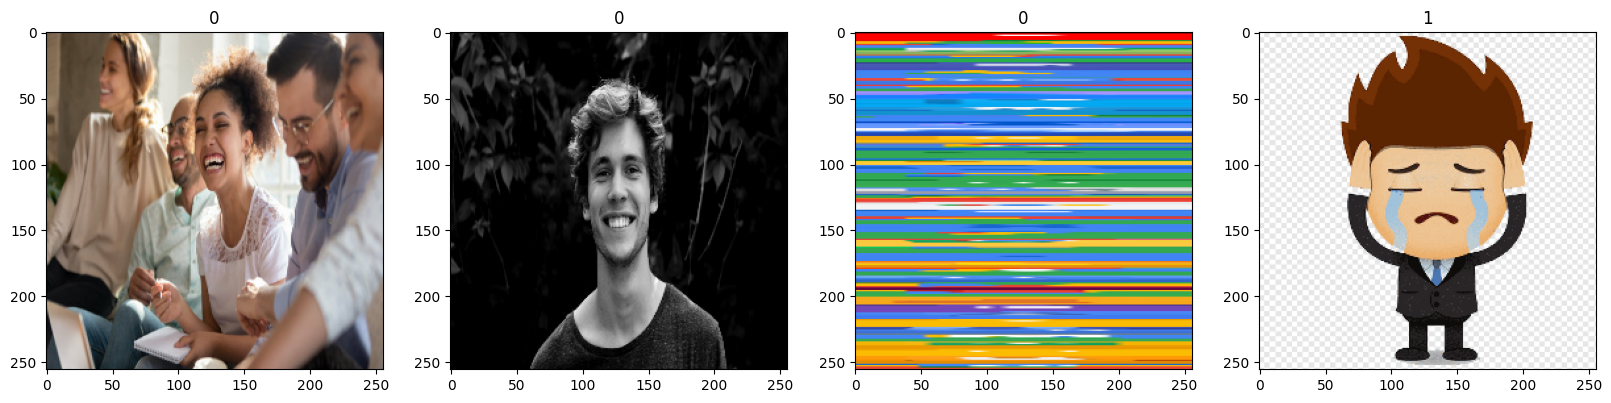

In [ ]:
fig , ax = plt.subplots(ncols=4,figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

In [ ]:
scaled=batch[0]/255
scaled.max()

In [ ]:
data = data.map(lambda x,y : (x/255,y))


In [ ]:
scaled_iterator= data.as_numpy_iterator()

In [ ]:
batch= scaled_iterator.next()

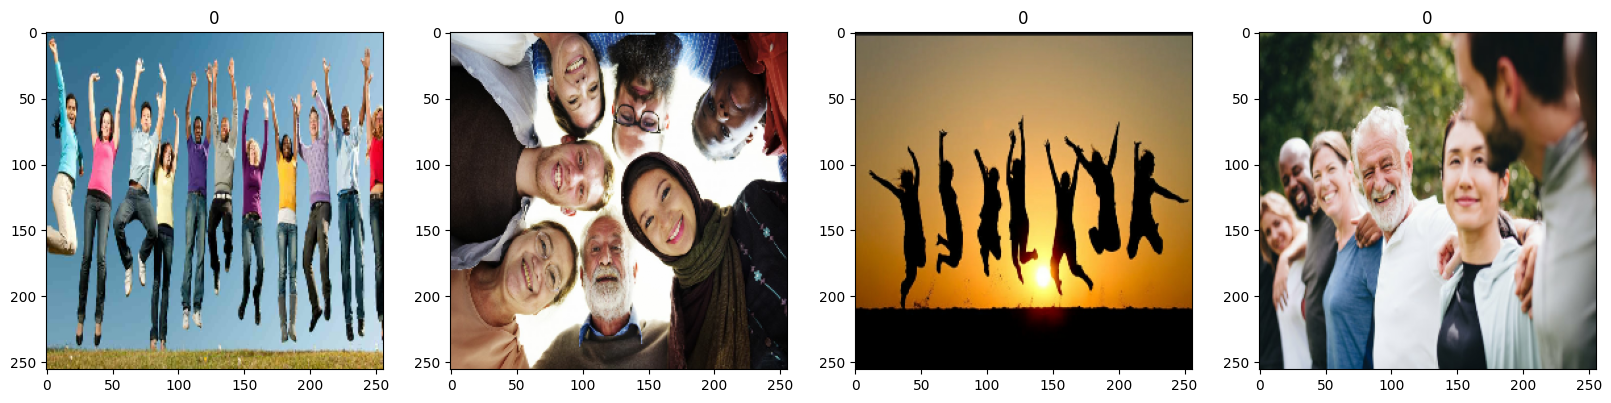

In [ ]:
fig , ax = plt.subplots(ncols=4,figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx])

In [ ]:
batch[0].max()

In [ ]:
len(data)

In [ ]:
train_size = int(len(data)*.7)
val_size = int(len(data)*.2)+1
test_size = int(len(data)*.1)+1

In [ ]:
train_size

In [ ]:
val_size

In [ ]:
test_size


In [ ]:
train_size+val_size+test_size

In [ ]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [ ]:
len(test)

BUILDING DEEP LEARNING MODEL

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense,Flatten

In [ ]:
model = Sequential()

In [ ]:
model.add(Conv2D(16,(3,3) ,1 , activation='relu', input_shape=(256,256,3)))
model.add(MaxPooling2D())
model.add(Conv2D(32,(3,3) ,1 , activation='relu'))
model.add(MaxPooling2D())
model.add(Conv2D(16,(3,3) ,1 , activation='relu'))
model.add(MaxPooling2D())

model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile('adam',loss=tf.losses.BinaryCrossentropy(),metrics=['accuracy'])

In [ ]:
model.summary()

In [ ]:
logdir = 'logs'


In [ ]:
tensorboard_callback= tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [ ]:
hist = model.fit(train,epochs=20,validation_data=val,callbacks=[tensorboard_callback])

In [ ]:
hist.history

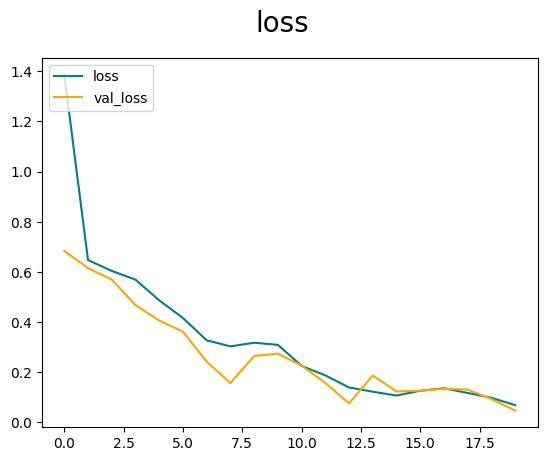

In [ ]:
fig = plt.figure()
plt.plot(hist.history['loss'],color='teal',label='loss')
plt.plot(hist.history['val_loss'],color='orange',label='val_loss')
fig.suptitle('loss',fontsize =20)
plt.legend(loc="upper left")
plt.show()

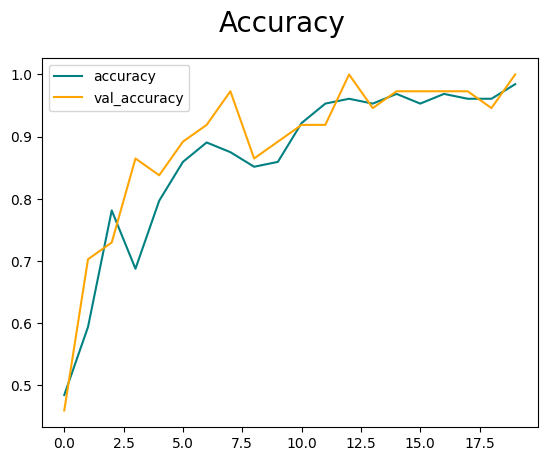

In [ ]:
fig = plt.figure()
plt.plot(hist.history['accuracy'],color='teal',label='accuracy')
plt.plot(hist.history['val_accuracy'],color='orange',label='val_accuracy')
fig.suptitle('Accuracy',fontsize =20)
plt.legend(loc="upper left")
plt.show()

In [ ]:
from tensorflow.keras.metrics import Precision, Recall,BinaryAccuracy

In [ ]:
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

In [ ]:
for batch in test.as_numpy_iterator():
    X,y=batch
    yhat= model.predict(X)
    pre.update_state(y,yhat)
    re.update_state(y,yhat)
    acc.update_state(y,yhat)
    
    

In [ ]:
print(f'Precision: {pre.result().numpy()},Recall: {re.result().numpy()},Accuracy:{acc.result().numpy()}')

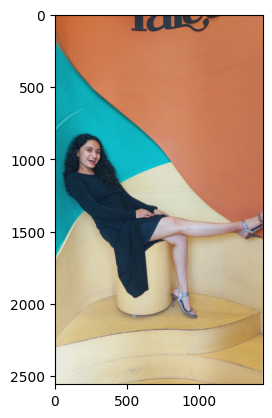

In [ ]:
img = cv2.imread('examples/sample.jpg')
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.show()

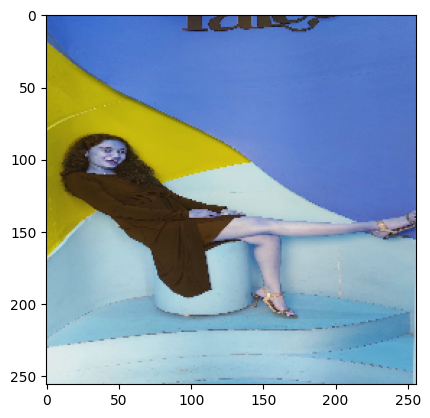

In [ ]:
resize = tf.image.resize(img,(256,256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [ ]:
yhat = model.predict(np.expand_dims(resize/255,0))

In [ ]:
if yhat>0.5:
    print('Predicted class is SAD :(')
else:
    print("Predicted class is HAPPY :D")

In [ ]:
from tensorflow.keras.models import load_model

In [ ]:
os.makedirs('models', exist_ok=True)
model.save(os.path.join('models','image-wise.h5'))

In [ ]:
new_model= load_model(os.path.join('models','image-wise.h5'))

In [ ]:
new_model

In [ ]:
yhat_new=new_model.predict(np.expand_dims(resize/255,0))

In [ ]:
if yhat_new>0.5:
    print('Predicted class is SAD :(')
else:
    print("Predicted class is HAPPY :D")